#Part 1 — Introduction and project setup

# Week 8: Explainable AI

## Customer Churn Prediction Using Random Forest and SHAP

**Course:** Data Science & Analytics  
**Assignment Code:** AVX-DS-W8  
**Project Type:** Machine Learning Model Interpretation

### 1. Introduction

The purpose of this project is to understand how and why a machine learning model makes predictions. A prediction alone may not be sufficient for a business because decision-makers also need to understand which factors influence the model's output.

In this project, we use a customer churn dataset to predict whether a customer is likely to leave a telecommunications company. We train a Random Forest Classifier and use permutation feature importance and SHAP to interpret its predictions.

### 2. Objectives

- Train and evaluate a machine learning classification model.
- Identify the ten most important features.
- Generate and interpret SHAP visualizations.
- Explain at least five individual predictions.
- Compare permutation importance and SHAP.
- Investigate potential bias, data imbalance, and model limitations.
- Provide practical recommendations for the business.

### 3. Business Problem

A telecommunications company wants to understand which customer characteristics are associated with customer churn. The model's explanations may help the company investigate customer retention opportunities.

**Important:** Feature importance indicates associations with the model's predictions. It does not, by itself, establish that a feature causes a customer to leave.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn shap reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.5 MB/s eta 0:00:00


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

os.makedirs("outputs", exist_ok=True)

RANDOM_STATE = 42

print("Libraries imported successfully.")
print("SHAP version:", shap.__version__)

Libraries imported successfully.
SHAP version: 0.52.0


#Part 2 — Load and understand the dataset

## 4. Dataset Description

This project uses the IBM Telco Customer Churn dataset, a publicly available dataset containing telecommunications customer information.

The dataset includes customer demographics, service subscriptions, contract information, payment methods, monthly charges, total charges, and a churn label.

The target variable is `Churn`:

- `Yes`: the customer churned.
- `No`: the customer did not churn.

We will inspect the dataset before training the model to understand its size, columns, data types, and target distribution.

Load the data

In [3]:
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully.
Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Inspect columns and data types

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary of numerical columns:")
display(df.describe())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Check missing values and duplicates

In [5]:
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values in the target:")
print(df["Churn"].value_counts(dropna=False))

Missing values before cleaning:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0

Unique values in the target:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Visualize the target distribution

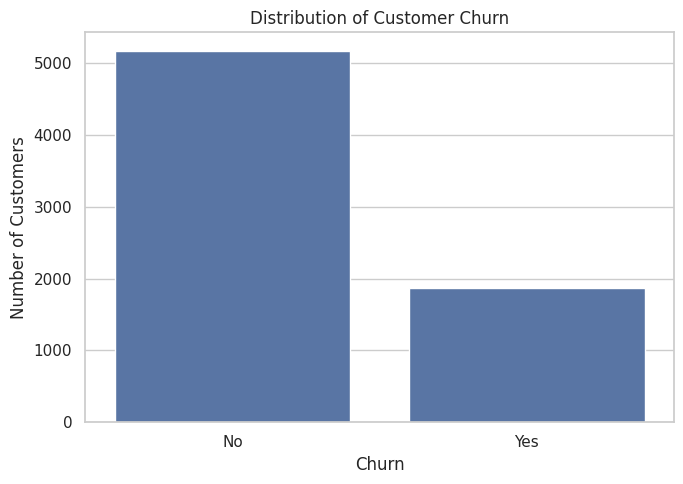

Churn percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig("outputs/churn_distribution.png", dpi=300)
plt.show()

print("Churn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

#Part 3 — Clean and prepare the data

## 5. Data Cleaning and Preparation

Before training, we prepare the data for machine learning.

The `customerID` column is removed because it identifies a customer rather than describing their behavior. The `TotalCharges` column is converted to a numeric data type because it may initially be stored as text.

Missing numerical values will be imputed using the training data's median, while missing categorical values will be filled using the most frequent category. Categorical variables will be encoded into numeric columns.

The preprocessing steps will be fitted within a machine learning pipeline to reduce the risk of data leakage from the test set into training.

Clean the dataset

In [7]:
data = df.copy()

# Convert TotalCharges to numeric values
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Remove the customer identifier
data = data.drop(columns=["customerID"])

# Remove rows without a valid target label
data = data.dropna(subset=["Churn"]).copy()

# Encode the target:
# Yes = 1, No = 0
data["Churn"] = data["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Remove any rows whose target could not be encoded
data = data.dropna(subset=["Churn"]).copy()
data["Churn"] = data["Churn"].astype(int)

print("Cleaned dataset shape:", data.shape)
print("\nMissing values after target cleaning:")
display(data.isnull().sum().sort_values(ascending=False).head(10))

print("\nTarget counts:")
display(data["Churn"].value_counts().sort_index())

Cleaned dataset shape: (7043, 20)

Missing values after target cleaning:


,0
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0



Target counts:


,count
Churn,
0,5174
1,1869


Separate features and target

In [8]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nTarget meaning:")
print("0 = Customer stayed")
print("1 = Customer churned")

Number of input features: 19
Number of target values: 7043

Target meaning:
0 = Customer stayed
1 = Customer churned


Identify numeric and categorical features

In [9]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Split into training and test sets

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Training samples: 5634
Testing samples: 1409

Training target distribution:


,proportion
Churn,
0,0.735
1,0.265



Testing target distribution:


,proportion
Churn,
0,0.735
1,0.265


Build the preprocessing pipeline

In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


#Part 4 — Train the Random Forest model

## 6. Model Selection

The selected model is a Random Forest Classifier. It combines predictions from multiple decision trees and can model nonlinear relationships between customer features and churn.

Random Forest is suitable for this assignment because it can be evaluated using classification metrics and interpreted with permutation importance and SHAP.

The target variable is `Churn`, where 1 represents churn and 0 represents a customer who stayed. The model's performance must be measured on the held-out test set before its explanations are interpreted.

Create and train the model

In [12]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


Make predictions

In [13]:
y_pred = model.predict(X_test)

# Probability of class 1: customer churn
y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions generated.")
print("First 10 predicted labels:", y_pred[:10])
print("First 10 churn probabilities:", np.round(y_prob[:10], 3))

Predictions generated.
First 10 predicted labels: [0 1 0 0 0 1 0 0 0 1]
First 10 churn probabilities: [0.009 0.8   0.071 0.331 0.045 0.646 0.475 0.163 0.008 0.545]


Evaluate model performance

In [14]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(metrics_df.round(4))

metrics_df.to_csv("outputs/model_metrics.csv", index=False)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.7814
1,Precision,0.5801
2,Recall,0.6390
3,F1-score,0.6081
4,ROC-AUC,0.8338



Classification report:
              precision    recall  f1-score   support

      Stayed       0.86      0.83      0.85      1035
     Churned       0.58      0.64      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



Confusion matrix

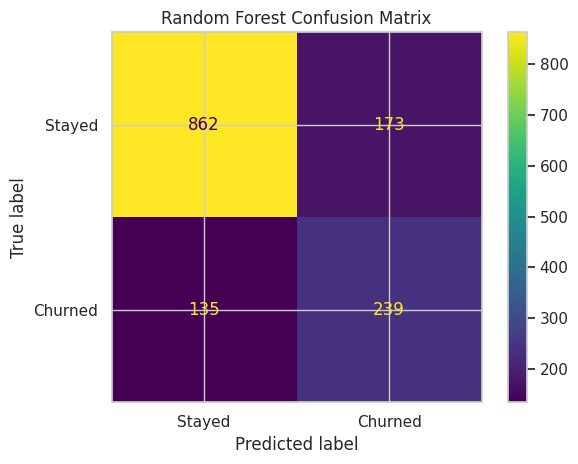

In [15]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()

plt.savefig("outputs/confusion_matrix.png", dpi=300)
plt.show()

What the metrics mean:
- Accuracy: proportion of all test predictions that were correct.
- Precision: among predicted churn cases, the proportion that actually churned.
- Recall: among actual churn cases, the proportion the model identified.
- F1-score: a combined measure of precision and recall.
- ROC-AUC: how well the model ranks churn cases above non-churn cases across classification thresholds.

#Part 5 — Global feature importance

## 7. Global Feature Importance Using Permutation Importance

Global feature importance helps us understand which original input features have the greatest influence on the model's performance across the test dataset.

We use permutation importance. This method measures how much the evaluation score changes when the values of one feature are randomly shuffled. If shuffling a feature substantially reduces the score, the model may rely on that feature for its predictions.

We use ROC-AUC as the scoring metric and compare the ten most important features. Importance values are measures of model reliance, not proof of causation.

Calculate permutation importance

In [16]:
perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

print("Top 10 features using permutation importance:")
display(permutation_df.head(10).round(5))

permutation_df.to_csv(
    "outputs/permutation_importance.csv",
    index=False
)

Top 10 features using permutation importance:


,Feature,Importance,Std
14,Contract,0.04759,0.00347
4,tenure,0.02414,0.00162
18,TotalCharges,0.01739,0.00182
7,InternetService,0.01614,0.00809
8,OnlineSecurity,0.00454,0.00239
11,TechSupport,0.00274,0.00132
3,Dependents,0.00109,0.00101
2,Partner,0.00103,0.00101
9,OnlineBackup,0.00100,0.00325
1,SeniorCitizen,0.00068,0.00114


Plot the top 10 features

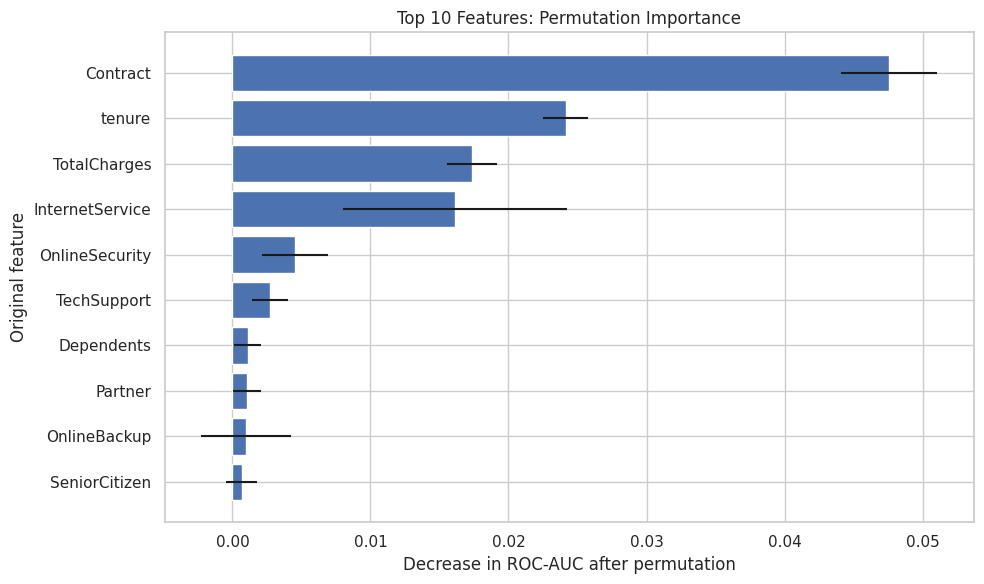

In [17]:
top10_permutation = permutation_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_permutation["Feature"],
    top10_permutation["Importance"],
    xerr=top10_permutation["Std"]
)

plt.xlabel("Decrease in ROC-AUC after permutation")
plt.ylabel("Original feature")
plt.title("Top 10 Features: Permutation Importance")
plt.tight_layout()

plt.savefig(
    "outputs/permutation_top10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Permutation Importance

The horizontal bar chart ranks the original customer features according to how much shuffling each feature affects the model's ROC-AUC score.

Features with larger positive importance values have a greater effect on the model's measured performance when their information is disrupted. Values near zero indicate that shuffling a feature had little measured effect under this evaluation setup. Negative values can occur because of sampling variation or interactions between features.

The actual top-ranked features and their importance values are reported in the output table. These results will be compared with SHAP in a later section.

#Part 6 — SHAP analysis

## 8. SHAP (SHapley Additive exPlanations)

SHAP is a model explanation method that estimates how individual features contribute to a prediction relative to a baseline.

In this project, we use SHAP with the trained Random Forest classifier. We explain the churn class (class 1).

We will produce:

1. A SHAP summary plot showing feature contributions across multiple customers.
2. A SHAP feature-importance bar plot.
3. An individual SHAP waterfall plot.

For binary classification, positive SHAP values generally push the model output toward the churn class, while negative values push it away from the churn class. The precise output scale depends on the SHAP explainer configuration, so we will interpret the plotted values in the context of this model rather than treating them automatically as percentage points.

Prepare the data for SHAP

In [18]:
# Get the preprocessing and trained classifier from the pipeline
trained_preprocessor = model.named_steps["preprocessor"]
trained_classifier = model.named_steps["classifier"]

# Transform the test data using the already-fitted preprocessing steps
X_test_processed = trained_preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Get readable feature names after one-hot encoding
feature_names = trained_preprocessor.get_feature_names_out()

X_test_encoded = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Encoded test data shape:", X_test_encoded.shape)
print("Number of encoded features:", len(feature_names))

display(X_test_encoded.head())

Encoded test data shape: (1409, 45)
Number of encoded features: 45


,numeric__SeniorCitizen,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,categorical__gender_Female,categorical__gender_Male,categorical__Partner_No,categorical__Partner_Yes,categorical__Dependents_No,categorical__Dependents_Yes,...,categorical__StreamingMovies_Yes,categorical__Contract_Month-to-month,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_No,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check
437,0.0,72.0,114.05,8468.20,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2280,1.0,8.0,100.15,908.55,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2235,0.0,41.0,78.35,3211.20,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4460,0.0,18.0,78.20,1468.75,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3761,0.0,72.0,82.65,5919.35,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


Calculate SHAP values

In [19]:
# Use a reproducible sample to keep explanation generation manageable
shap_sample = X_test_encoded.iloc[:300].copy()

explainer = shap.TreeExplainer(trained_classifier)
shap_explanation = explainer(shap_sample)

# Extract SHAP values for the churn class (class 1)
raw_values = shap_explanation.values
raw_base_values = shap_explanation.base_values

if raw_values.ndim == 3:
    # Shape: samples x features x classes
    shap_values_churn = raw_values[:, :, 1]

    if np.ndim(raw_base_values) == 2:
        base_values_churn = raw_base_values[:, 1]
    else:
        base_values_churn = raw_base_values

elif isinstance(raw_values, list):
    # Compatibility with older SHAP output formats
    shap_values_churn = raw_values[1]

    if isinstance(raw_base_values, list):
        base_values_churn = raw_base_values[1]
    else:
        base_values_churn = raw_base_values

else:
    # Single-output format
    shap_values_churn = raw_values
    base_values_churn = raw_base_values

base_values_churn = np.asarray(base_values_churn)

if base_values_churn.ndim > 0 and base_values_churn.size > 1:
    base_values_churn = base_values_churn.reshape(-1)

print("SHAP analysis completed.")
print("SHAP values shape:", shap_values_churn.shape)

SHAP analysis completed.
SHAP values shape: (300, 45)


SHAP summary plot

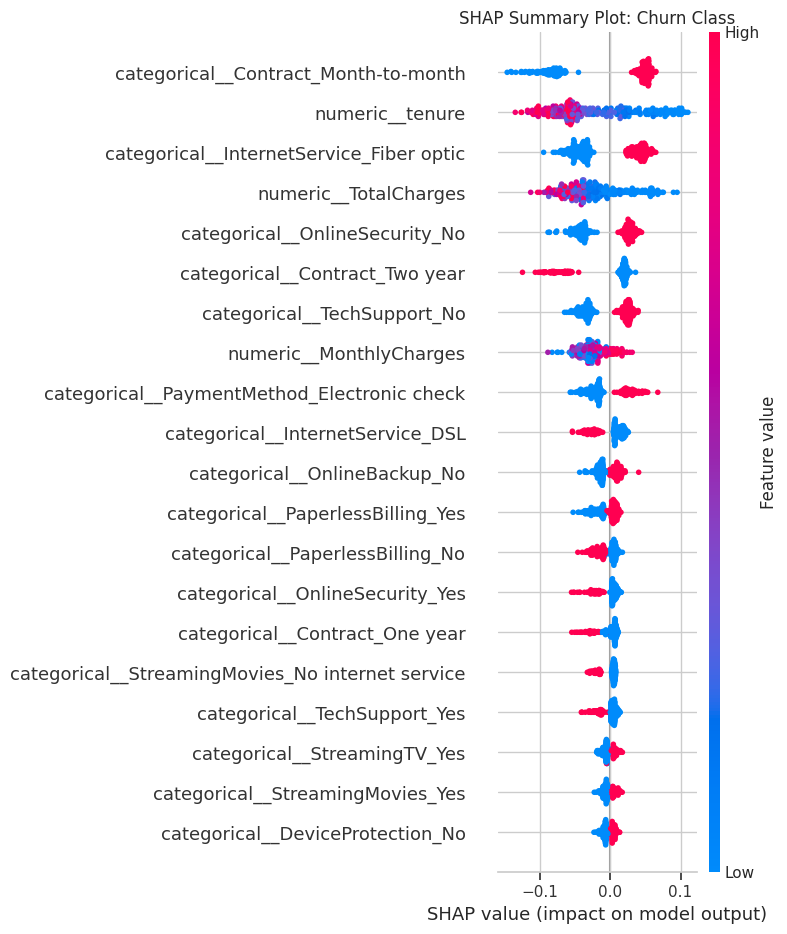

In [20]:
plt.figure()

shap.summary_plot(
    shap_values_churn,
    shap_sample,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot: Churn Class")
plt.tight_layout()

plt.savefig(
    "outputs/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SHAP feature-importance plot

Top 10 encoded features by mean absolute SHAP:


,Feature,MeanAbsoluteSHAP
36,categorical__Contract_Month-to-month,0.06481
1,numeric__tenure,0.05781
16,categorical__InternetService_Fiber optic,0.04373
3,numeric__TotalCharges,0.04176
18,categorical__OnlineSecurity_No,0.03557
38,categorical__Contract_Two year,0.03267
27,categorical__TechSupport_No,0.03016
2,numeric__MonthlyCharges,0.02748
43,categorical__PaymentMethod_Electronic check,0.02548
15,categorical__InternetService_DSL,0.01726


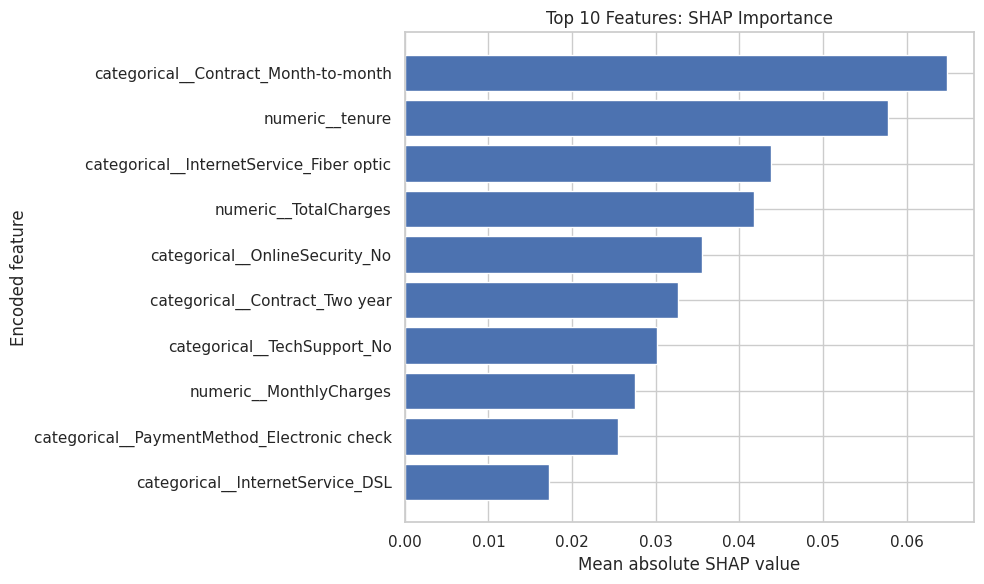

In [21]:
mean_abs_shap = np.abs(shap_values_churn).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsoluteSHAP": mean_abs_shap
}).sort_values("MeanAbsoluteSHAP", ascending=False)

print("Top 10 encoded features by mean absolute SHAP:")
display(shap_importance_df.head(10).round(5))

shap_importance_df.to_csv(
    "outputs/shap_feature_importance.csv",
    index=False
)

top10_shap = shap_importance_df.head(10).sort_values(
    "MeanAbsoluteSHAP",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_shap["Feature"],
    top10_shap["MeanAbsoluteSHAP"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Encoded feature")
plt.title("Top 10 Features: SHAP Importance")
plt.tight_layout()

plt.savefig(
    "outputs/shap_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Explain one individual prediction

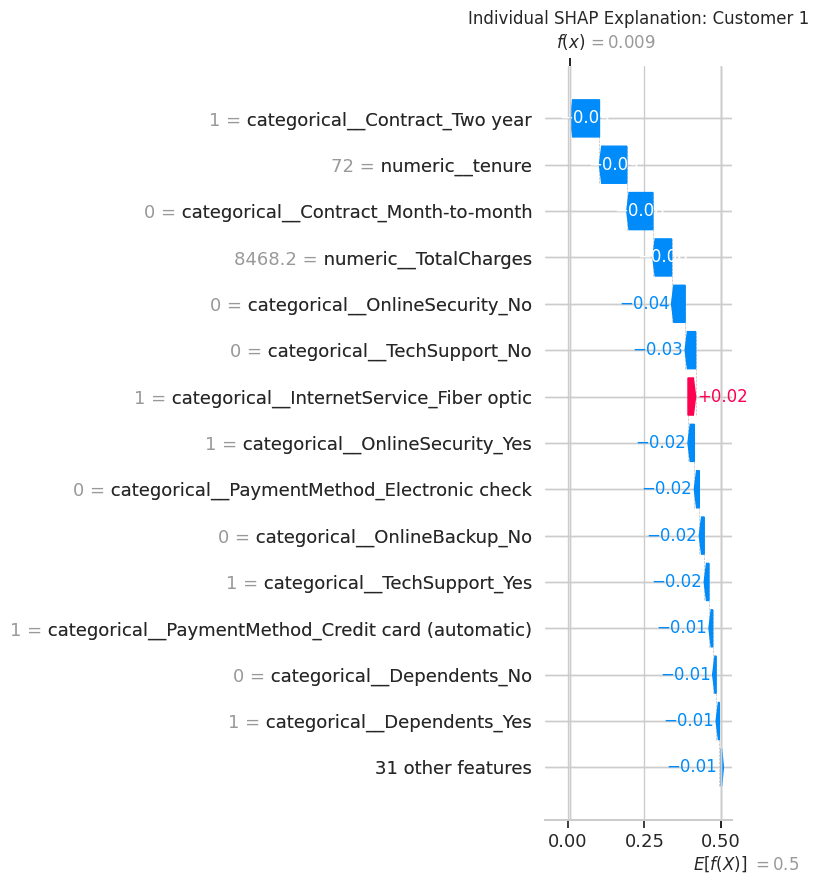

Actual churn label: 0
Predicted churn label: 0
Predicted churn probability: 0.0093


In [22]:
# Explain the first customer in our SHAP sample
customer_position = 0

base_value = base_values_churn[customer_position]

if np.ndim(base_value) > 0:
    base_value = np.asarray(base_value).item()

individual_explanation = shap.Explanation(
    values=shap_values_churn[customer_position],
    base_values=float(base_value),
    data=shap_sample.iloc[customer_position].values,
    feature_names=list(feature_names)
)

shap.plots.waterfall(
    individual_explanation,
    max_display=15,
    show=False
)

plt.title("Individual SHAP Explanation: Customer 1")
plt.tight_layout()

plt.savefig(
    "outputs/shap_individual_customer1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual churn label:", int(y_test.iloc[customer_position]))
print("Predicted churn label:", int(y_pred[customer_position]))
print("Predicted churn probability:", round(float(y_prob[customer_position]), 4))

#Part 7 — Individual prediction analysis: five customers

## 9. Individual Prediction Analysis

Global feature importance summarizes model behavior across many records, but individual explanations help us understand particular predictions.

We examine five customers from the held-out test set. For each customer, we record the original input values, actual churn outcome, predicted outcome, predicted churn probability, and the strongest positive and negative SHAP contributions.

A positive contribution pushes the model output toward churn; a negative contribution pushes it away from churn. These are explanations of the model, not proof that the identified factors caused the customer's behavior.

Create the five-customer analysis table

In [23]:
individual_rows = []

number_of_customers = min(5, len(shap_sample))

for i in range(number_of_customers):
    customer_input = X_test.iloc[i]
    shap_series = pd.Series(
        shap_values_churn[i],
        index=feature_names
    )

    # Largest positive contributions
    positive_factors = shap_series.sort_values(
        ascending=False
    ).head(3)

    # Largest negative contributions
    negative_factors = shap_series.sort_values(
        ascending=True
    ).head(3)

    individual_rows.append({
        "Test_Row": str(X_test.index[i]),
        "Actual_Churn": int(y_test.iloc[i]),
        "Predicted_Churn": int(y_pred[i]),
        "Predicted_Churn_Probability": round(float(y_prob[i]), 4),
        "Input_Contract": customer_input.get("Contract", "N/A"),
        "Input_Tenure": customer_input.get("tenure", "N/A"),
        "Input_MonthlyCharges": customer_input.get("MonthlyCharges", "N/A"),
        "Input_TotalCharges": customer_input.get("TotalCharges", "N/A"),
        "Top_Positive_SHAP_Factors": "; ".join(
            f"{name} ({value:.4f})"
            for name, value in positive_factors.items()
        ),
        "Top_Negative_SHAP_Factors": "; ".join(
            f"{name} ({value:.4f})"
            for name, value in negative_factors.items()
        )
    })

individual_df = pd.DataFrame(individual_rows)

display(individual_df)

individual_df.to_csv(
    "outputs/five_individual_predictions.csv",
    index=False
)

,Test_Row,Actual_Churn,Predicted_Churn,Predicted_Churn_Probability,Input_Contract,Input_Tenure,Input_MonthlyCharges,Input_TotalCharges,Top_Positive_SHAP_Factors,Top_Negative_SHAP_Factors
0,437,0,0,0.0093,Two year,72,114.05,8468.20,categorical__InternetService_Fiber optic (0.02...,categorical__Contract_Two year (-0.0946); nume...
1,2280,0,1,0.7995,Month-to-month,8,100.15,908.55,categorical__Contract_Month-to-month (0.0592);...,categorical__TechSupport_No (-0.0477); categor...
2,2235,0,0,0.0711,One year,41,78.35,3211.20,categorical__Contract_Two year (0.0188); categ...,categorical__Contract_Month-to-month (-0.0878)...
3,4460,0,0,0.3313,Month-to-month,18,78.20,1468.75,categorical__Contract_Month-to-month (0.0462);...,categorical__TechSupport_No (-0.0529); numeric...
4,3761,0,0,0.0449,Two year,72,82.65,5919.35,categorical__TechSupport_No (0.0261); categori...,categorical__Contract_Month-to-month (-0.0846)...


Generate individual plots for five customers

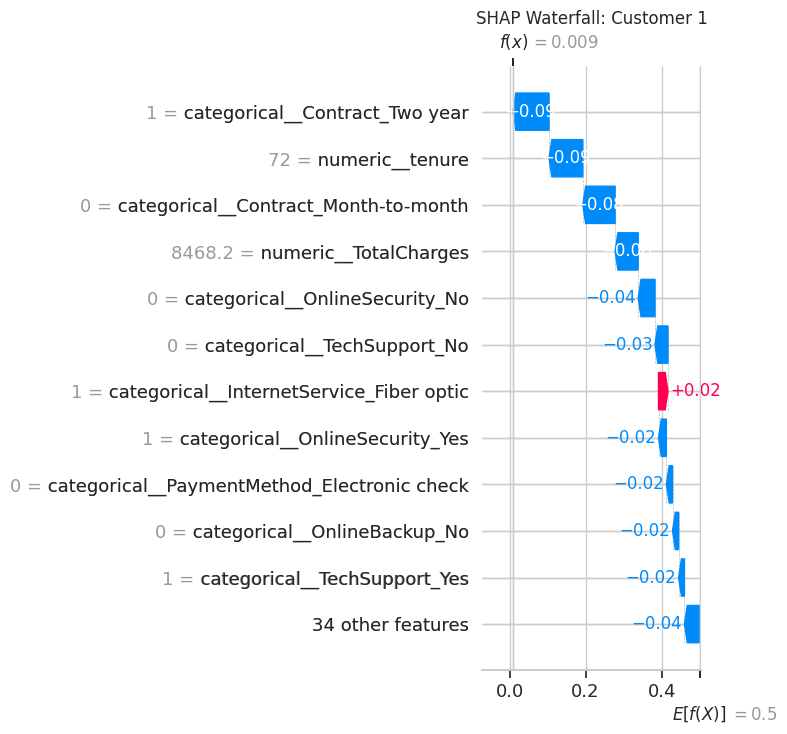

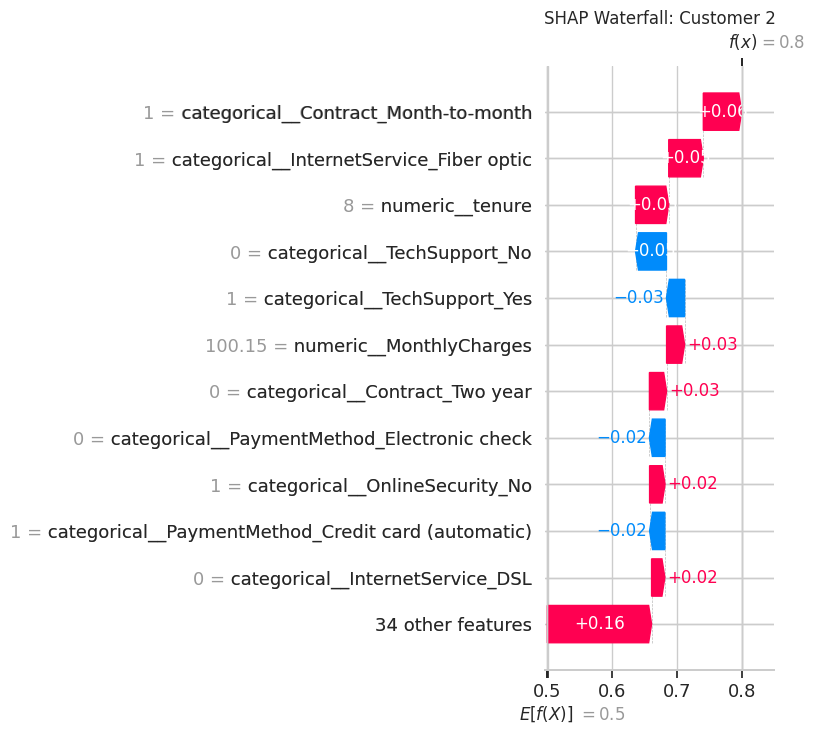

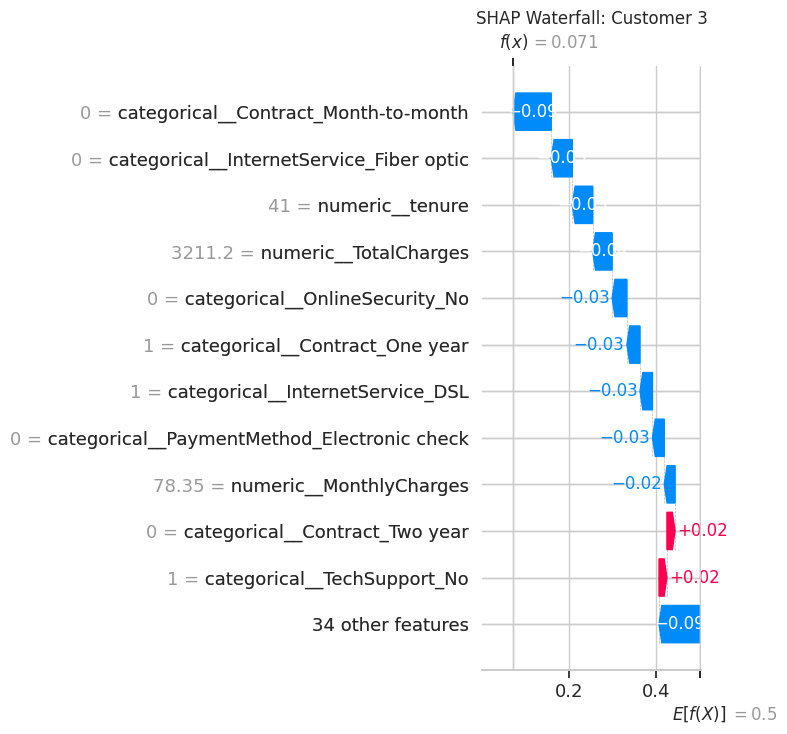

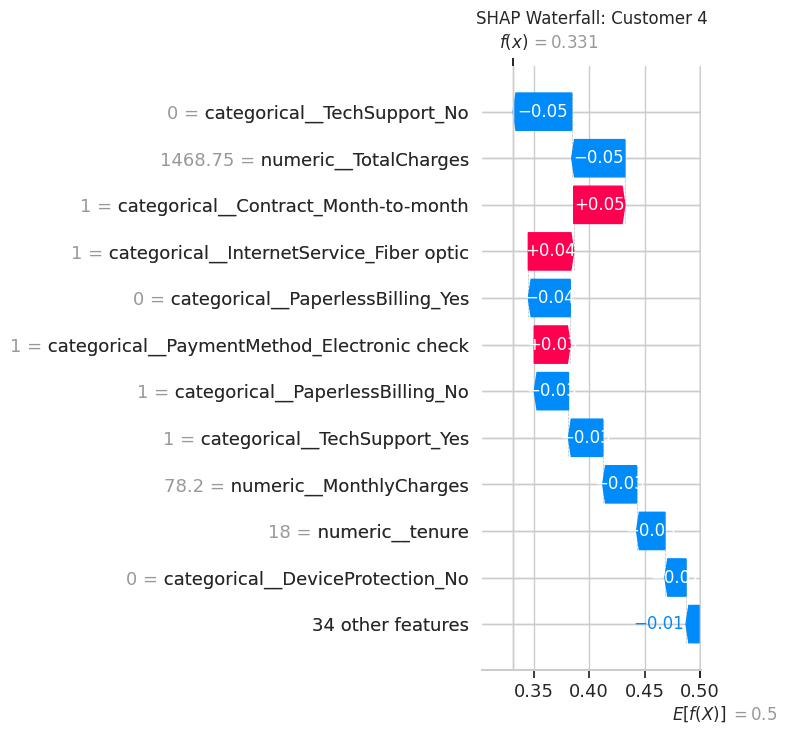

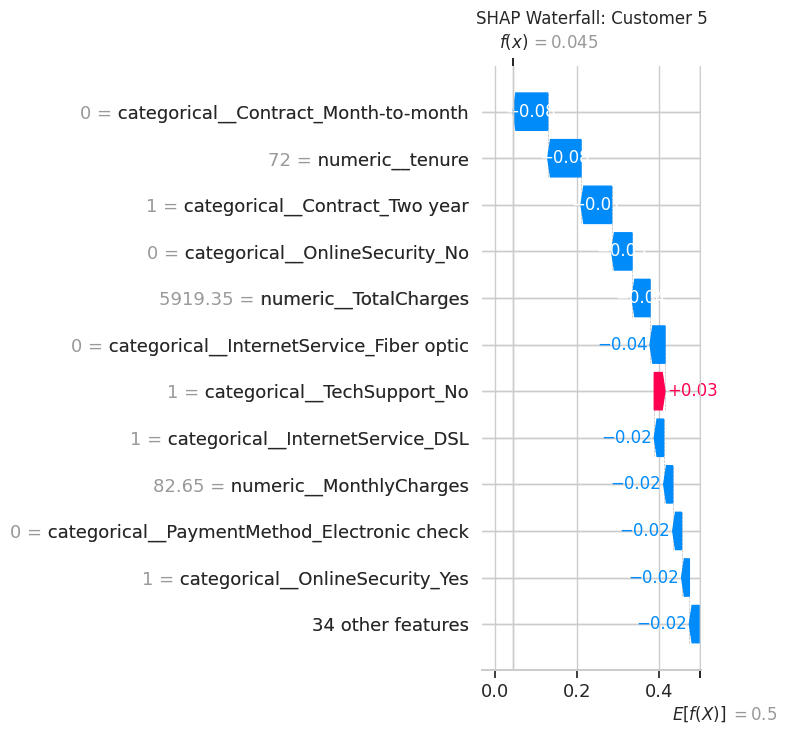

In [24]:
for i in range(number_of_customers):
    base_value = base_values_churn[i]

    if np.ndim(base_value) > 0:
        base_value = np.asarray(base_value).item()

    explanation = shap.Explanation(
        values=shap_values_churn[i],
        base_values=float(base_value),
        data=shap_sample.iloc[i].values,
        feature_names=list(feature_names)
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=False
    )

    plt.title(f"SHAP Waterfall: Customer {i + 1}")
    plt.tight_layout()

    plt.savefig(
        f"outputs/shap_customer_{i + 1}.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Interpretation of the Five Predictions

Use the generated table and individual waterfall plots to describe each customer.

For each case, state:

1. The customer's observed input values.
2. Whether the customer actually churned in the test dataset.
3. Whether the model predicted churn.
4. The predicted churn probability.
5. The strongest positive and negative SHAP contributions.
6. Why those contributions help explain the model's output.

A correct prediction occurs when the predicted label matches the actual label. A false positive occurs when the model predicts churn but the customer did not churn. A false negative occurs when the model predicts that the customer will stay but the customer actually churned.

Discuss these outcomes using the actual results from the notebook. Do not invent a customer's values or claim that a feature caused churn.

#Part 8 — Compare permutation importance and SHAP

## 10. Comparison of Explanation Methods

Permutation importance and SHAP explain model behavior in different ways.

Permutation importance measures how much model performance changes when a feature is shuffled. SHAP measures feature contributions to individual model outputs and can summarize their magnitude across a sample.

The two methods may rank features differently because they measure different quantities. Correlated features can substitute for one another, and SHAP can distinguish between one-hot encoded categories while permutation importance here evaluates original input columns.

We compare the rankings and identify features that appear in both methods.

Compare the top 10 lists

In [25]:
permutation_top10 = permutation_df.head(10)["Feature"].tolist()

shap_top10 = shap_importance_df.head(10)["Feature"].tolist()

comparison_df = pd.DataFrame({
    "Rank": range(1, 11),
    "Permutation_Importance_Feature": permutation_top10,
    "SHAP_Feature": shap_top10
})

display(comparison_df)

# Exact feature names can differ because SHAP uses encoded categories.
# This comparison shows the two rankings side by side.
permutation_set = set(permutation_top10)
shap_set = set(shap_top10)

print("Exact feature-name overlap:", sorted(permutation_set & shap_set))
print("Features unique to permutation top 10:",
      sorted(permutation_set - shap_set))
print("Features unique to SHAP top 10:",
      sorted(shap_set - permutation_set))

comparison_df.to_csv(
    "outputs/explanation_method_comparison.csv",
    index=False
)

,Rank,Permutation_Importance_Feature,SHAP_Feature
0,1,Contract,categorical__Contract_Month-to-month
1,2,tenure,numeric__tenure
2,3,TotalCharges,categorical__InternetService_Fiber optic
3,4,InternetService,numeric__TotalCharges
4,5,OnlineSecurity,categorical__OnlineSecurity_No
5,6,TechSupport,categorical__Contract_Two year
6,7,Dependents,categorical__TechSupport_No
7,8,Partner,numeric__MonthlyCharges
8,9,OnlineBackup,categorical__PaymentMethod_Electronic check
9,10,SeniorCitizen,categorical__InternetService_DSL


Exact feature-name overlap: []
Features unique to permutation top 10: ['Contract', 'Dependents', 'InternetService', 'OnlineBackup', 'OnlineSecurity', 'Partner', 'SeniorCitizen', 'TechSupport', 'TotalCharges', 'tenure']
Features unique to SHAP top 10: ['categorical__Contract_Month-to-month', 'categorical__Contract_Two year', 'categorical__InternetService_DSL', 'categorical__InternetService_Fiber optic', 'categorical__OnlineSecurity_No', 'categorical__PaymentMethod_Electronic check', 'categorical__TechSupport_No', 'numeric__MonthlyCharges', 'numeric__TotalCharges', 'numeric__tenure']


Compare SHAP after grouping encoded features

Top original features after aggregating SHAP values:


,Original_Feature,MeanAbsoluteSHAP
0,Contract,0.10718
3,InternetService,0.06687
18,tenure,0.05781
7,OnlineSecurity,0.05016
15,TechSupport,0.04430
16,TotalCharges,0.04176
10,PaymentMethod,0.03815
4,MonthlyCharges,0.02748
6,OnlineBackup,0.02281
8,PaperlessBilling,0.02075


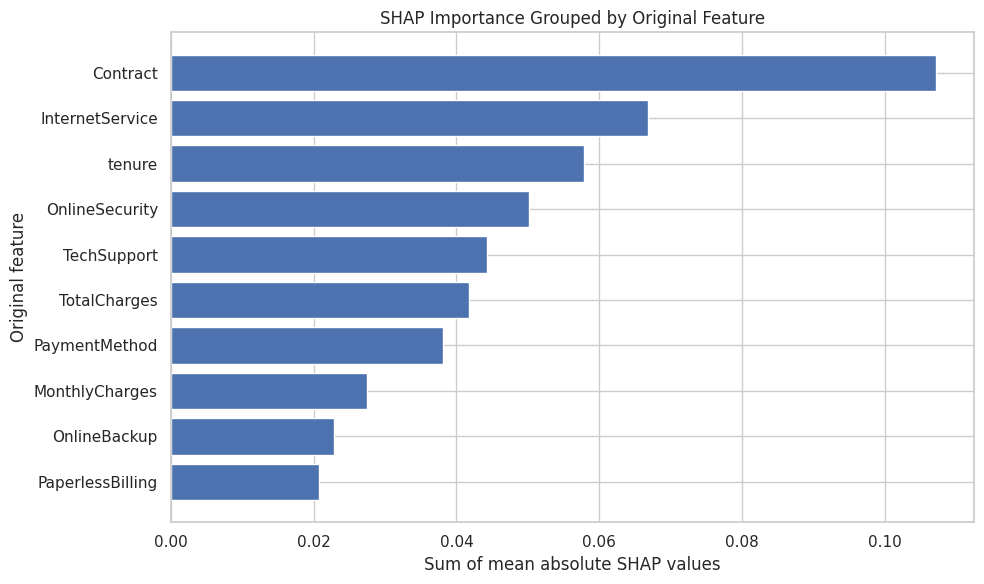

In [26]:
def get_original_feature(encoded_name):
    # ColumnTransformer names begin with "numeric__" or "categorical__".
    if encoded_name.startswith("numeric__"):
        return encoded_name.replace("numeric__", "", 1)

    if encoded_name.startswith("categorical__"):
        remaining = encoded_name.replace("categorical__", "", 1)

        # Match the longest original categorical column name.
        for col in sorted(categorical_features, key=len, reverse=True):
            if remaining == col or remaining.startswith(col + "_"):
                return col

    return encoded_name

shap_importance_df["Original_Feature"] = (
    shap_importance_df["Feature"].map(get_original_feature)
)

shap_original_df = (
    shap_importance_df.groupby("Original_Feature", as_index=False)
    ["MeanAbsoluteSHAP"].sum()
    .sort_values("MeanAbsoluteSHAP", ascending=False)
)

print("Top original features after aggregating SHAP values:")
display(shap_original_df.head(10).round(5))

shap_original_df.to_csv(
    "outputs/shap_importance_original_features.csv",
    index=False
)

plt.figure(figsize=(10, 6))

plot_df = shap_original_df.head(10).sort_values(
    "MeanAbsoluteSHAP",
    ascending=True
)

plt.barh(
    plot_df["Original_Feature"],
    plot_df["MeanAbsoluteSHAP"]
)

plt.xlabel("Sum of mean absolute SHAP values")
plt.ylabel("Original feature")
plt.title("SHAP Importance Grouped by Original Feature")
plt.tight_layout()

plt.savefig(
    "outputs/shap_importance_original_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation of the Comparison

Compare the permutation importance results with the aggregated SHAP rankings.

Features that rank highly in both methods appear important under two different explanation approaches. Features that differ in rank may reflect differences in what the methods measure, correlations among inputs, or the distribution of values in the test sample.

The rankings should be discussed using the generated tables. A feature's ranking does not establish causation, and a low rank does not prove that a feature is irrelevant in every situation.

#Part 9 — Investigate bias and potential problems

## 11. Investigating Potential Bias and Model Limitations

A model may perform differently across customer groups or may rely on features that create unfair outcomes. We investigate the class distribution and compare prediction metrics across gender and senior-citizen groups.

This analysis does not automatically prove that the model is biased. Differences may have several explanations, including group sizes, differences in churn rates, measurement quality, or model performance.

We also review the most important features and discuss possible data leakage, proxy variables, and the limits of observational data.

Compare performance across groups

In [27]:
y_pred_series = pd.Series(y_pred, index=X_test.index)
y_prob_series = pd.Series(y_prob, index=X_test.index)

def calculate_group_metrics(X_data, y_actual, y_prediction, column):
    rows = []

    for group_name, group_indices in X_data.groupby(column).groups.items():
        actual = y_actual.loc[group_indices]
        predicted = y_prediction.loc[group_indices]

        rows.append({
            "Group_Column": column,
            "Group": str(group_name),
            "Sample_Size": len(group_indices),
            "Actual_Churn_Rate": actual.mean(),
            "Predicted_Churn_Rate": predicted.mean(),
            "Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            )
        })

    return pd.DataFrame(rows)

fairness_tables = []

for column in ["gender", "SeniorCitizen"]:
    if column in X_test.columns:
        fairness_tables.append(
            calculate_group_metrics(
                X_test, y_test, y_pred_series, column
            )
        )

fairness_df = pd.concat(fairness_tables, ignore_index=True)

display(fairness_df.round(4))

fairness_df.to_csv(
    "outputs/group_performance.csv",
    index=False
)

,Group_Column,Group,Sample_Size,Actual_Churn_Rate,Predicted_Churn_Rate,Accuracy,Precision,Recall
0,gender,Female,687,0.2809,0.2853,0.7802,0.6071,0.6166
1,gender,Male,722,0.2507,0.2992,0.7825,0.5556,0.6630
2,SeniorCitizen,0,1187,0.2325,0.2443,0.7944,0.5552,0.5833
3,SeniorCitizen,1,222,0.4414,0.5495,0.7117,0.6393,0.7959


Visualize group churn and prediction rates

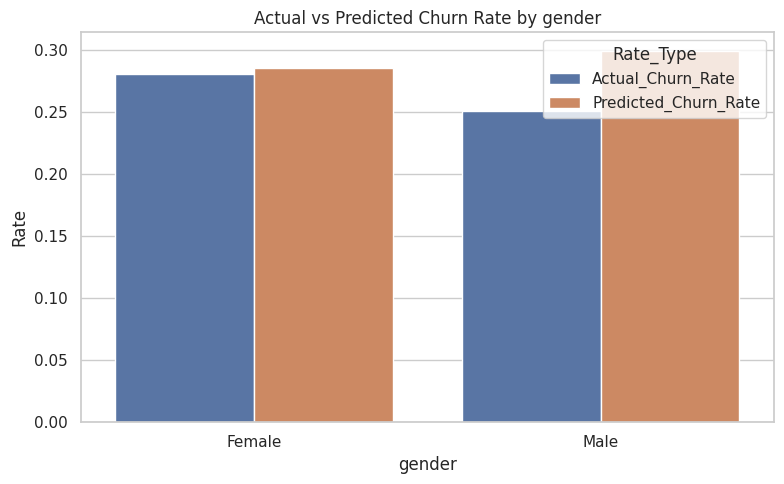

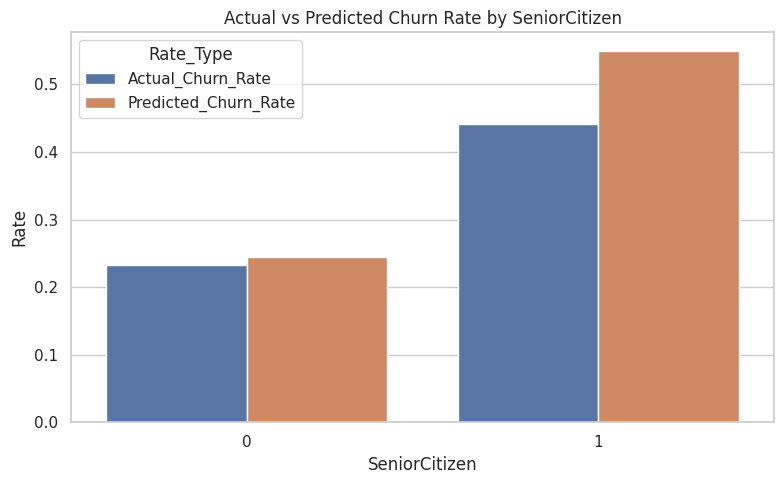

In [28]:
for column in ["gender", "SeniorCitizen"]:
    if column not in X_test.columns:
        continue

    group_summary = fairness_df[
        fairness_df["Group_Column"] == column
    ]

    group_plot = group_summary.melt(
        id_vars=["Group"],
        value_vars=["Actual_Churn_Rate", "Predicted_Churn_Rate"],
        var_name="Rate_Type",
        value_name="Rate"
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=group_plot,
        x="Group",
        y="Rate",
        hue="Rate_Type"
    )

    plt.title(f"Actual vs Predicted Churn Rate by {column}")
    plt.ylabel("Rate")
    plt.xlabel(column)
    plt.tight_layout()

    filename = f"outputs/group_rates_{column}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

Check the strongest features and model errors

In [29]:
print("Top 10 original features by permutation importance:")
display(permutation_df.head(10).round(5))

errors_df = X_test.copy()
errors_df["Actual_Churn"] = y_test
errors_df["Predicted_Churn"] = y_pred
errors_df["Predicted_Churn_Probability"] = y_prob

errors_df["Error_Type"] = np.select(
    [
        (errors_df["Actual_Churn"] == 0) &
        (errors_df["Predicted_Churn"] == 1),

        (errors_df["Actual_Churn"] == 1) &
        (errors_df["Predicted_Churn"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct Prediction"
)

print("\nPrediction error counts:")
display(errors_df["Error_Type"].value_counts())

print("\nExamples of incorrect predictions:")
display(
    errors_df[errors_df["Error_Type"] != "Correct Prediction"].head(10)
)

errors_df.to_csv(
    "outputs/test_predictions_and_errors.csv",
    index=True
)

Top 10 original features by permutation importance:


,Feature,Importance,Std
14,Contract,0.04759,0.00347
4,tenure,0.02414,0.00162
18,TotalCharges,0.01739,0.00182
7,InternetService,0.01614,0.00809
8,OnlineSecurity,0.00454,0.00239
11,TechSupport,0.00274,0.00132
3,Dependents,0.00109,0.00101
2,Partner,0.00103,0.00101
9,OnlineBackup,0.00100,0.00325
1,SeniorCitizen,0.00068,0.00114



Prediction error counts:


,count
Error_Type,
Correct Prediction,1101
False Positive,173
False Negative,135



Examples of incorrect predictions:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Predicted_Churn_Probability,Error_Type
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.799535,False Positive
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,0,1,0.645563,False Positive
2136,Male,0,No,Yes,15,Yes,Yes,Fiber optic,No,Yes,...,No,Month-to-month,Yes,Electronic check,91.00,1430.05,0,1,0.680950,False Positive
1838,Male,1,No,No,54,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Electronic check,90.05,4931.80,0,1,0.542510,False Positive
2488,Male,0,No,No,31,Yes,No,DSL,No,No,...,No,Month-to-month,Yes,Electronic check,55.25,1715.65,1,0,0.142269,False Negative
2519,Male,0,Yes,No,2,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,91.45,171.45,0,1,0.899217,False Positive
5400,Female,0,No,No,33,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Bank transfer (automatic),70.40,2406.10,0,1,0.567725,False Positive
3510,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,75.25,576.70,0,1,0.656483,False Positive
523,Female,0,No,No,23,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,No,Bank transfer (automatic),75.60,1758.60,1,0,0.452007,False Negative
5086,Male,0,No,No,45,Yes,No,No,No internet service,No internet service,...,No internet service,One year,Yes,Electronic check,20.40,930.45,1,0,0.011472,False Negative


### Interpretation of Potential Problems

The group analysis reports sample sizes, actual churn rates, predicted churn rates, accuracy, precision, and recall. Differences between groups should be examined in context rather than treated as proof of unfairness.

The class distribution should also be considered when interpreting accuracy and recall. The error table shows whether the model makes false-positive and false-negative predictions and can help identify situations requiring further investigation.

Potential limitations include historical patterns in the data, unequal group representation, correlated features, imperfect measurements, and the possibility that the model does not generalize to other companies or time periods. This analysis is a preliminary diagnostic, not a complete fairness audit.

#Part 10 — Answering the eight required questions

## 12. Required Explainability Questions

### 1. Why is explainability important in machine learning?

Explainability helps people understand the factors influencing a model's predictions. It supports debugging, transparency, accountability, and the identification of unexpected behavior. In business applications, explanations can help decision-makers evaluate whether predictions are reasonable before taking action.

### 2. What is the difference between global and local explanation?

Global explanation describes the model's overall behavior across a dataset. For example, a feature-importance chart ranks features according to their overall importance. Local explanation describes why the model made a prediction for one particular customer, such as an individual SHAP waterfall plot.

### 3. Why can feature importance and SHAP give different results?

Different methods measure different aspects of model behavior. Permutation importance measures the change in model performance after shuffling a feature, while SHAP estimates how features contribute to individual predictions. Correlated features, one-hot encoding, interactions, and the evaluation sample can cause the rankings to differ.

### 4. What does a positive SHAP value mean?

For the churn-class explanation in this project, a positive SHAP value generally pushes the model output toward the churn class relative to its baseline. It does not necessarily mean the customer will churn, and it does not prove that the feature caused churn.

### 5. What does a negative SHAP value mean?

A negative SHAP value generally pushes the model output away from the churn class and toward the non-churn class relative to the baseline. The overall prediction still depends on the combined contributions and the model's decision threshold.

### 6. Can an important feature always be considered a cause of the prediction? Why or why not?

No. Feature importance describes how a model uses information to make predictions, not necessarily a causal relationship. A feature may be correlated with another variable, act as a proxy, or reflect patterns in historical data. Establishing causality requires additional evidence and an appropriate causal analysis.

### 7. What problems can occur when we explain a model using a biased dataset?

Explanations from a biased dataset may reproduce historical discrimination, underrepresent certain groups, or emphasize misleading relationships. They can create false confidence in unfair or inaccurate decisions. Data quality, group representation, model performance across groups, and the meaning of important features should all be examined.

### 8. Can an explainable model still be wrong? Explain.

Yes. Explainability describes how a model reaches its output; it does not guarantee that the output is correct. A model may use incomplete or biased data, learn spurious patterns, or fail on new customers. Model evaluation, data validation, monitoring, and human oversight remain necessary.

#Part 11 — Business interpretation and recommendations

## 13. Business Interpretation

The purpose of the analysis is to help a telecommunications company understand the behavior of its churn prediction model.

The permutation-importance table identifies original input features that most affect model performance. The SHAP plots provide additional information about how features contribute to individual predictions.

The business should use these findings as evidence for further investigation, not as automatic instructions to make decisions about individual customers.

### Practical Business Recommendations

1. **Investigate the strongest predictors.** Review the top-ranked features from permutation importance and aggregated SHAP. Determine whether these relationships are understandable, actionable, and consistent with the company's operational knowledge.

2. **Evaluate retention strategies through controlled tests.** Develop appropriate retention interventions and measure whether they reduce churn. Do not assume that changing an important feature will necessarily change customer behavior.

3. **Review model errors and group performance.** Monitor false negatives, false positives, and differences in performance across customer groups. Investigate whether some customers are systematically missed or incorrectly flagged.

4. **Monitor performance over time.** Re-evaluate the model as customer behavior, pricing, services, and business conditions change.

5. **Keep human oversight.** Use model predictions to support customer-service decisions rather than making consequential decisions solely from automated scores.

Create a business summary from your actual results

In [30]:
print("BUSINESS SUMMARY")
print("=" * 60)

print(f"Test accuracy:  {accuracy:.4f}")
print(f"Test precision: {precision:.4f}")
print(f"Test recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print(f"Test ROC-AUC:   {roc_auc:.4f}")

print("\nTop 5 original features by permutation importance:")

for _, row in permutation_df.head(5).iterrows():
    print(
        f"- {row['Feature']}: "
        f"{row['Importance']:.5f} "
        f"(standard deviation: {row['Std']:.5f})"
    )

print("\nUse these measured results to support your report.")
print("Do not describe feature importance as proof of causation.")

BUSINESS SUMMARY
Test accuracy:  0.7814
Test precision: 0.5801
Test recall:    0.6390
Test F1-score:  0.6081
Test ROC-AUC:   0.8338

Top 5 original features by permutation importance:
- Contract: 0.04759 (standard deviation: 0.00347)
- tenure: 0.02414 (standard deviation: 0.00162)
- TotalCharges: 0.01739 (standard deviation: 0.00182)
- InternetService: 0.01614 (standard deviation: 0.00809)
- OnlineSecurity: 0.00454 (standard deviation: 0.00239)

Use these measured results to support your report.
Do not describe feature importance as proof of causation.
